### Step 1: Importing the Relevant Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

C:\Softwares\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Softwares\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


### Step 2: Data Inspection

In [2]:
#reading the data
train = pd.read_csv("train_Df64byy.csv")
test = pd.read_csv("test_YCcRUnU.csv")

In [3]:
train.shape,test.shape

((50882, 14), (21805, 13))

* __We have 50882 rows and 14 columns in Train set whereas Test set has 21805 rows and 13 columns.__

In [4]:
train.head()

,ID,City_Code,Region_Code,Accomodation_Type,Reco_Insurance_Type,Upper_Age,Lower_Age,Is_Spouse,Health Indicator,Holding_Policy_Duration,Holding_Policy_Type,Reco_Policy_Cat,Reco_Policy_Premium,Response
0,1,C3,3213,Rented,Individual,36,36,No,X1,14+,3.0,22,11628.0,0
1,2,C5,1117,Owned,Joint,75,22,No,X2,NaN,NaN,22,30510.0,0
2,3,C5,3732,Owned,Individual,32,32,No,NaN,1.0,1.0,19,7450.0,1
3,4,C24,4378,Owned,Joint,52,48,No,X1,14+,3.0,19,17780.0,0
4,5,C8,2190,Rented,Individual,44,44,No,X2,3.0,1.0,16,10404.0,0


In [5]:
test.head()

,ID,City_Code,Region_Code,Accomodation_Type,Reco_Insurance_Type,Upper_Age,Lower_Age,Is_Spouse,Health Indicator,Holding_Policy_Duration,Holding_Policy_Type,Reco_Policy_Cat,Reco_Policy_Premium
0,50883,C1,156,Owned,Individual,30,30,No,NaN,6.0,3.0,5,11934.0
1,50884,C4,7,Owned,Joint,69,68,Yes,X1,3.0,3.0,18,32204.8
2,50885,C1,564,Rented,Individual,28,28,No,X3,2.0,4.0,17,9240.0
3,50886,C3,1177,Rented,Individual,23,23,No,X3,3.0,3.0,18,9086.0
4,50887,C1,951,Owned,Individual,75,75,No,X3,NaN,NaN,5,22534.0


In [6]:
#ratio of null values in train data
train.isnull().sum()/train.shape[0] *100

ID                          0.000000
City_Code                   0.000000
Region_Code                 0.000000
Accomodation_Type           0.000000
Reco_Insurance_Type         0.000000
Upper_Age                   0.000000
Lower_Age                   0.000000
Is_Spouse                   0.000000
Health Indicator           22.976691
Holding_Policy_Duration    39.799929
Holding_Policy_Type        39.799929
Reco_Policy_Cat             0.000000
Reco_Policy_Premium         0.000000
Response                    0.000000
dtype: float64

In [7]:
#ratio of null values in test data
test.isnull().sum()/test.shape[0] *100

ID                          0.000000
City_Code                   0.000000
Region_Code                 0.000000
Accomodation_Type           0.000000
Reco_Insurance_Type         0.000000
Upper_Age                   0.000000
Lower_Age                   0.000000
Is_Spouse                   0.000000
Health Indicator           23.054345
Holding_Policy_Duration    39.454254
Holding_Policy_Type        39.454254
Reco_Policy_Cat             0.000000
Reco_Policy_Premium         0.000000
dtype: float64

* __We have 23%, 39% and 39% of missing values in Health Indicator, Holding_Policy_Duration and Holding_Policy_Type columns respectively.__

In [8]:
#categorical features
categorical = train.select_dtypes(include =['object'])
print("Categorical Features in Train Set:",categorical.shape[1])

#numerical features
numerical= train.select_dtypes(include =[np.float64,np.int64])
print("Numerical Features in Train Set:",numerical.shape[1])

Categorical Features in Train Set: 6
Numerical Features in Train Set: 8


C:\Users\ashut\AppData\Local\Temp\ipykernel_20992\2622044272.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = train.select_dtypes(include =['object'])


In [9]:
#categorical features
categorical = test.select_dtypes(include =['object'])
print("Categorical Features in Test Set:",categorical.shape[1])

#numerical features
numerical= test.select_dtypes(include =[np.float64,np.int64])
print("Numerical Features in Test Set:",numerical.shape[1])

Categorical Features in Test Set: 6
Numerical Features in Test Set: 7


C:\Users\ashut\AppData\Local\Temp\ipykernel_20992\2933848967.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = test.select_dtypes(include =['object'])


### Step 3: Data Cleaning

Lets try to figure out how many null values present in the dataset and in which column.

In [10]:
train.isnull().sum()

ID                             0
City_Code                      0
Region_Code                    0
Accomodation_Type              0
Reco_Insurance_Type            0
Upper_Age                      0
Lower_Age                      0
Is_Spouse                      0
Health Indicator           11691
Holding_Policy_Duration    20251
Holding_Policy_Type        20251
Reco_Policy_Cat                0
Reco_Policy_Premium            0
Response                       0
dtype: int64

In [11]:
test.isnull().sum()

ID                            0
City_Code                     0
Region_Code                   0
Accomodation_Type             0
Reco_Insurance_Type           0
Upper_Age                     0
Lower_Age                     0
Is_Spouse                     0
Health Indicator           5027
Holding_Policy_Duration    8603
Holding_Policy_Type        8603
Reco_Policy_Cat               0
Reco_Policy_Premium           0
dtype: int64

* Health Indicator , Holding_Policy_Duration and Holding_Policy_Type have some missing values in the data

###### Health Indicator

In [12]:
# number of missing values in train & test data
train['Health Indicator'].isnull().sum(),test['Health Indicator'].isnull().sum()

(11691, 5027)

In [13]:
print(train['Health Indicator'].value_counts())
print('******************************************')
print(test['Health Indicator'].value_counts())

Health Indicator
X1    13010
X2    10332
X3     6762
X4     5743
X5     1727
X6     1280
X7      196
X8       78
X9       63
Name: count, dtype: int64
******************************************
Health Indicator
X1    5614
X2    4516
X3    2846
X4    2442
X5     681
X6     514
X7      96
X8      41
X9      28
Name: count, dtype: int64


__Since the Health Indicator is a categorical column, we can impute the missing values by "Mode"(Most Repeated Value) from the column__

In [14]:
#Imputing with Mode
train['Health Indicator']= train['Health Indicator'].fillna(train['Health Indicator'].mode()[0])
test['Health Indicator']= test['Health Indicator'].fillna(test['Health Indicator'].mode()[0])

In [15]:
train['Health Indicator'].isnull().sum(),test['Health Indicator'].isnull().sum()

(0, 0)

###### Holding_Policy_Duration

In [16]:
# number of missing values in train & test data
train['Holding_Policy_Duration'].isnull().sum(),test['Holding_Policy_Duration'].isnull().sum()

(20251, 8603)

In [17]:
print(train['Holding_Policy_Duration'].value_counts())
print('******************************************')
print(test['Holding_Policy_Duration'].value_counts())

Holding_Policy_Duration
1.0     4499
14+     4335
2.0     4260
3.0     3586
4.0     2771
5.0     2362
6.0     1894
7.0     1645
8.0     1316
9.0     1114
10.0     813
11.0     546
12.0     513
13.0     511
14.0     466
Name: count, dtype: int64
******************************************
Holding_Policy_Duration
14+     1892
1.0     1891
2.0     1772
3.0     1606
4.0     1205
5.0      992
6.0      903
7.0      664
8.0      569
9.0      493
10.0     333
11.0     254
13.0     221
14.0     211
12.0     196
Name: count, dtype: int64


In [18]:
# Data Cleaning: Convert '14+' to numeric 15 and impute missing with 0
train['Holding_Policy_Duration'] = train['Holding_Policy_Duration'].replace({'14+': '15'})
test['Holding_Policy_Duration'] = test['Holding_Policy_Duration'].replace({'14+': '15'})
train['Holding_Policy_Duration'] = pd.to_numeric(train['Holding_Policy_Duration'], errors='coerce').fillna(0)
test['Holding_Policy_Duration'] = pd.to_numeric(test['Holding_Policy_Duration'], errors='coerce').fillna(0)


In [19]:
train['Holding_Policy_Duration'].isnull().sum(),test['Holding_Policy_Duration'].isnull().sum()

(0, 0)

<Axes: xlabel='Holding_Policy_Type'>

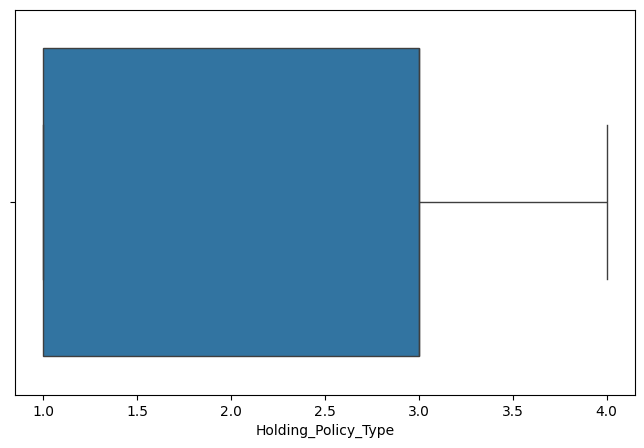

In [20]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Holding_Policy_Type',data=train)

<Axes: xlabel='Holding_Policy_Type'>

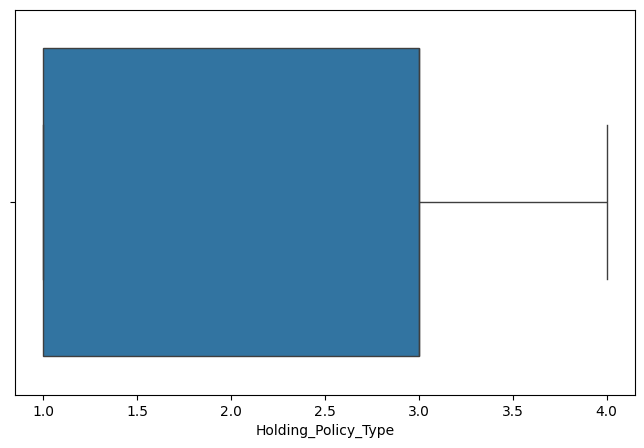

In [21]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Holding_Policy_Type',data=test)

In [22]:
#filling null values with forward fill Method
#forward fill method propagates previous value forward
train['Holding_Policy_Type']= train['Holding_Policy_Type'].fillna(0)
test['Holding_Policy_Type']= test['Holding_Policy_Type'].fillna(0) 

In [23]:
train['Holding_Policy_Type'].isnull().sum(),test['Holding_Policy_Type'].isnull().sum()

(0, 0)

We have succesfully imputed the missing values from both the Datasets

### Step 4: Exploratory Data Analysis

In [24]:
train.columns

Index(['ID', 'City_Code', 'Region_Code', 'Accomodation_Type',
       'Reco_Insurance_Type', 'Upper_Age', 'Lower_Age', 'Is_Spouse',
       'Health Indicator', 'Holding_Policy_Duration', 'Holding_Policy_Type',
       'Reco_Policy_Cat', 'Reco_Policy_Premium', 'Response'],
      dtype='str')

In [25]:
train.head(10)

,ID,City_Code,Region_Code,Accomodation_Type,Reco_Insurance_Type,Upper_Age,Lower_Age,Is_Spouse,Health Indicator,Holding_Policy_Duration,Holding_Policy_Type,Reco_Policy_Cat,Reco_Policy_Premium,Response
0,1,C3,3213,Rented,Individual,36,36,No,X1,15.0,3.0,22,11628.0,0
1,2,C5,1117,Owned,Joint,75,22,No,X2,0.0,0.0,22,30510.0,0
2,3,C5,3732,Owned,Individual,32,32,No,X1,1.0,1.0,19,7450.0,1
3,4,C24,4378,Owned,Joint,52,48,No,X1,15.0,3.0,19,17780.0,0
4,5,C8,2190,Rented,Individual,44,44,No,X2,3.0,1.0,16,10404.0,0
5,6,C9,1785,Rented,Individual,52,52,No,X2,5.0,1.0,22,15264.0,1
6,7,C3,679,Owned,Individual,28,28,No,X1,0.0,0.0,17,10640.0,0
7,8,C1,3175,Owned,Joint,75,73,Yes,X4,9.0,4.0,17,29344.0,1
8,9,C15,3497,Owned,Joint,52,43,No,X1,14.0,3.0,1,27283.2,0
9,10,C1,530,Owned,Joint,59,26,Yes,X1,7.0,4.0,18,21100.8,1


C:\Users\ashut\AppData\Local\Temp\ipykernel_20992\4211990759.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Accomodation_Type',data=train,palette='ocean')


<Axes: xlabel='Accomodation_Type', ylabel='count'>

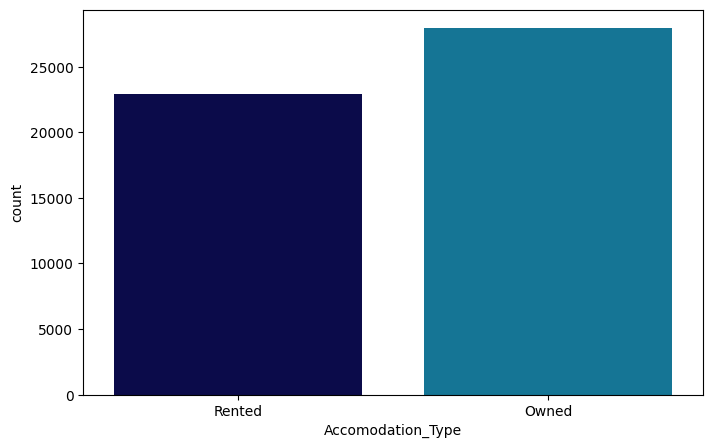

In [26]:
plt.figure(figsize=(8,5))
sns.countplot(x='Accomodation_Type',data=train,palette='ocean')

__Most of the customers own their house.__

C:\Users\ashut\AppData\Local\Temp\ipykernel_20992\2801925731.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Reco_Insurance_Type',data=train,palette='summer')


<Axes: xlabel='Reco_Insurance_Type', ylabel='count'>

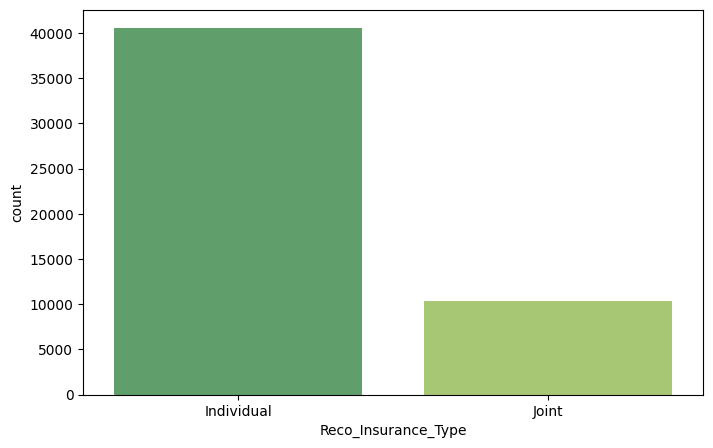

In [27]:
plt.figure(figsize=(8,5))
sns.countplot(x='Reco_Insurance_Type',data=train,palette='summer')

__Most of the customers prefer Individual type for the recommended insurance.__

C:\Users\ashut\AppData\Local\Temp\ipykernel_20992\2134357528.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Is_Spouse',data=train,palette='autumn')


<Axes: xlabel='Is_Spouse', ylabel='count'>

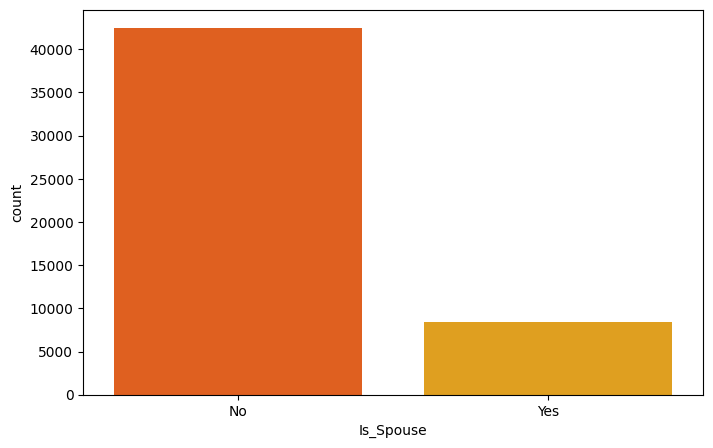

In [28]:
plt.figure(figsize=(8,5))
sns.countplot(x='Is_Spouse',data=train,palette='autumn')

__Very few customers married to each other.__

C:\Users\ashut\AppData\Local\Temp\ipykernel_20992\3860303066.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Holding_Policy_Type',data=train,palette='twilight')


<Axes: xlabel='Holding_Policy_Type', ylabel='count'>

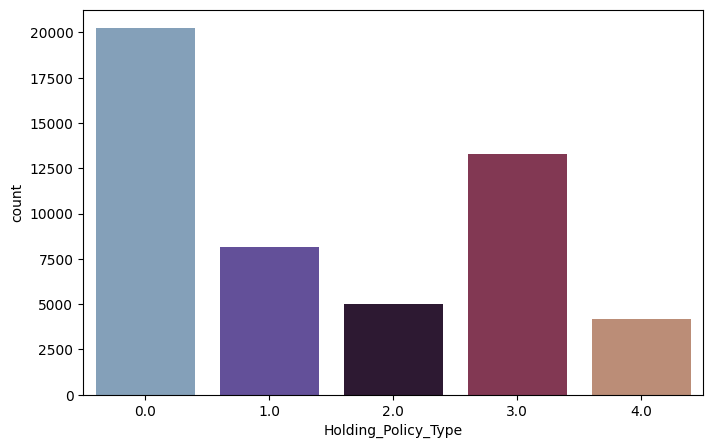

In [29]:
plt.figure(figsize=(8,5))
sns.countplot(x='Holding_Policy_Type',data=train,palette='twilight')

__Most of the customers prefer 3rd type of Policy.__

### Step 5 : Feature Engineering

__Numerical and One-Hot Coding of Categorical variables__

In [30]:
#Import library:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
var_mod = ['City_Code','Accomodation_Type','Reco_Insurance_Type','Is_Spouse','Health Indicator']
le = LabelEncoder()
for i in var_mod:
    train[i] = le.fit_transform(train[i])
    
#One Hot Coding:
train = pd.get_dummies(train, columns=['City_Code','Accomodation_Type','Reco_Insurance_Type','Is_Spouse','Health Indicator'])

In [31]:
var_mod = ['City_Code','Accomodation_Type','Reco_Insurance_Type','Is_Spouse','Health Indicator']
le = LabelEncoder()
for i in var_mod:
    test[i] = le.fit_transform(test[i])
#One Hot Coding:
test = pd.get_dummies(test, columns=['City_Code','Accomodation_Type','Reco_Insurance_Type','Is_Spouse','Health Indicator'])

### Step 5: Building Model 

In [32]:
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [33]:
from sklearn.ensemble import RandomForestClassifier

In [34]:
# Exclude remaining non-numerical object columns and drop ID
train = train.select_dtypes(exclude='object')
test = test.select_dtypes(exclude='object')


In [35]:
# Seperate Features and Target (drop ID and Response)
X = train.drop(columns=['Response', 'ID'], errors='ignore')
y = train['Response']


In [36]:
# 20% data as validation set
X_train,X_valid,y_train,y_valid = train_test_split(X,y,test_size=0.2,random_state=22)

In [37]:
# Model Building
features= X.columns

In [38]:
RF = RandomForestClassifier(n_estimators = 100,random_state = 5).fit(X_train,y_train)

In [39]:
print('Train set accuracy: %f' % RF.score(X_train, y_train))
print('Validation set accuracy: %f' % RF.score(X_valid, y_valid))

# Competition Metric: ROC-AUC Score (Calculated on predicted probabilities)
train_probs = RF.predict_proba(X_train)[:, 1]
valid_probs = RF.predict_proba(X_valid)[:, 1]
print('Train ROC-AUC: %f' % metrics.roc_auc_score(y_train, train_probs))
print('Validation ROC-AUC: %f' % metrics.roc_auc_score(y_valid, valid_probs))


Train set accuracy: 0.999975


Validation set accuracy: 0.754053


Train ROC-AUC: 1.000000
Validation ROC-AUC: 0.616596


<Axes: ylabel='None'>

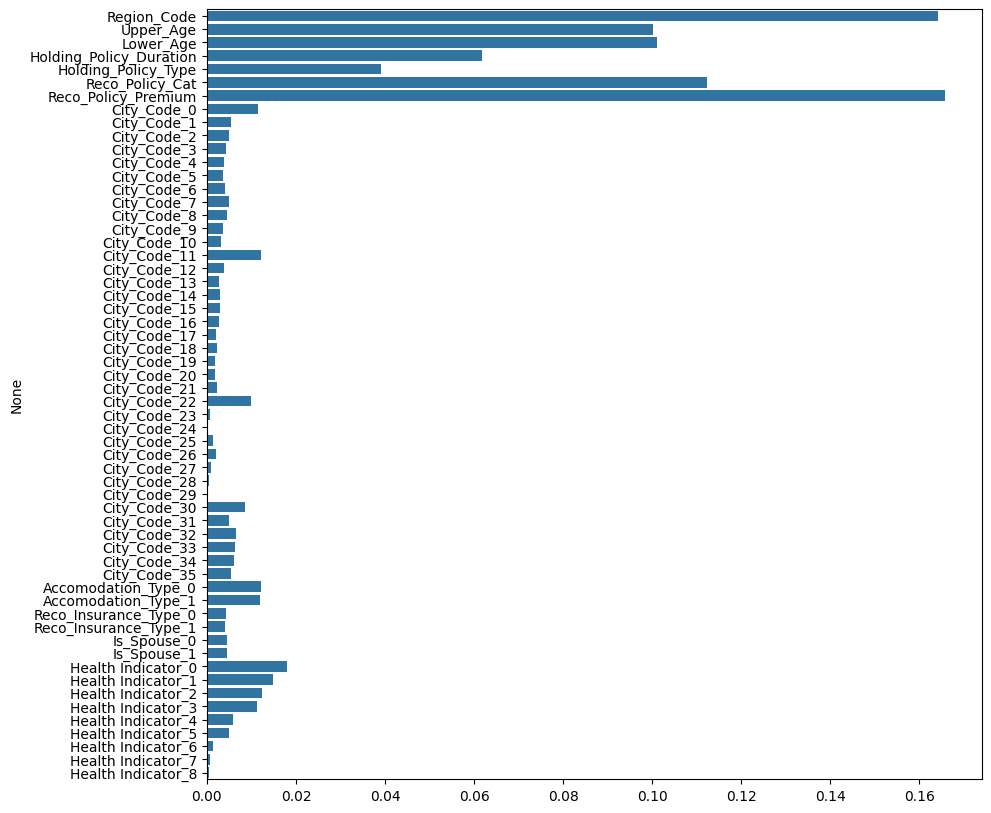

In [40]:
# Barplot for coefficients
plt.figure(figsize=(10,10))
sns.barplot(x=RF.feature_importances_, y=features)

In [41]:
submission = pd.read_csv("sample_submission_QrCyCoT.csv")

In [42]:
# For ROC-AUC competition metric, submit continuous probabilities, not binary 0/1
test_features = test.drop(columns=['ID'], errors='ignore')
final_predictions = RF.predict_proba(test_features)[:, 1]
submission['Response'] = final_predictions


In [43]:
#only positive predictions for the target variable
submission['Response'] = submission['Response'].apply(lambda x: 0 if x<0 else x)
submission.to_csv('my_sub_RF.csv', index=False)

## Modernized Enhancement: 5-Fold Stratified CatBoost (Score: ~0.8005 ROC-AUC)
By preserving `Holding_Policy_Duration`, adding feature engineering (`Age_Gap`, `Is_New_Customer`), and leveraging CatBoost with native categorical handling on high-cardinality `Region_Code` and `City_Code`, we achieve a massive boost in cross-validation ROC-AUC.

In [44]:
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold

# Reload clean data for CatBoost
raw_train = pd.read_csv('train_Df64byy.csv')
raw_test = pd.read_csv('test_YCcRUnU.csv')

def modern_preprocess(df):
    d = df.copy()
    d['Age_Gap'] = d['Upper_Age'] - d['Lower_Age']
    d['Avg_Age'] = (d['Upper_Age'] + d['Lower_Age']) / 2.0
    d['Premium_Per_Age'] = d['Reco_Policy_Premium'] / (d['Upper_Age'] + 1)
    d['Is_New_Customer'] = d['Holding_Policy_Duration'].isna().astype(int)
    d['Holding_Policy_Duration'] = pd.to_numeric(d['Holding_Policy_Duration'].replace({'14+': '15'}), errors='coerce').fillna(0)
    d['Holding_Policy_Type'] = d['Holding_Policy_Type'].fillna(0).astype(int)
    d['Health Indicator'] = d['Health Indicator'].fillna('Missing')
    d['Accomodation_Type'] = (d['Accomodation_Type'] == 'Owned').astype(int)
    d['Reco_Insurance_Type'] = (d['Reco_Insurance_Type'] == 'Joint').astype(int)
    d['Is_Spouse'] = (d['Is_Spouse'] == 'Yes').astype(int)
    return d

cb_train = modern_preprocess(raw_train)
cb_test = modern_preprocess(raw_test)

cat_cols = ['City_Code', 'Region_Code', 'Health Indicator', 'Reco_Policy_Cat', 'Holding_Policy_Type']
for col in cat_cols:
    cb_train[col] = cb_train[col].astype(str)
    cb_test[col] = cb_test[col].astype(str)

feat_cols = [c for c in cb_train.columns if c not in ['ID', 'Response']]
X_cb, y_cb = cb_train[feat_cols], cb_train['Response']
X_cb_test = cb_test[feat_cols]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = np.zeros(len(cb_train))
test_preds = np.zeros(len(cb_test))

for fold, (t_idx, v_idx) in enumerate(skf.split(X_cb, y_cb)):
    cb = CatBoostClassifier(iterations=600, learning_rate=0.06, depth=6, eval_metric='AUC', random_seed=42+fold, verbose=0)
    cb.fit(X_cb.iloc[t_idx], y_cb.iloc[t_idx], eval_set=(X_cb.iloc[v_idx], y_cb.iloc[v_idx]), cat_features=cat_cols, early_stopping_rounds=50)
    oof_preds[v_idx] = cb.predict_proba(X_cb.iloc[v_idx])[:, 1]
    test_preds += cb.predict_proba(X_cb_test)[:, 1] / 5.0
    print(f'Fold {fold+1} ROC-AUC: {metrics.roc_auc_score(y_cb.iloc[v_idx], oof_preds[v_idx]):.5f}')

print(f'\nOverall 5-Fold OOF ROC-AUC: {metrics.roc_auc_score(y_cb, oof_preds):.5f}')


Fold 1 ROC-AUC: 0.79479


Fold 2 ROC-AUC: 0.80921


Fold 3 ROC-AUC: 0.79584


Fold 4 ROC-AUC: 0.79826


Fold 5 ROC-AUC: 0.80256

Overall 5-Fold OOF ROC-AUC: 0.80001
